In [7]:
## building a basic deepagent
import os
from dotenv import load_dotenv

load_dotenv()
os.environ["GQO_API_KEY"] = os.getenv("GROQ_API_KEY")
if not os.getenv("Tavily_APT_KEY"):
    os.environ["Tavily_API_KEY"] = os.getenv("Tavily_API_KEY")



In [19]:
## websearch tool for deep agent
from tavily import TavilyClient
from typing import Literal
tavily_client = TavilyClient(api_key=os.getenv("Tavily_API_KEY"))

def web_search(query:str,max_results:int=2,topic: Literal["sports","news","finance","general"]="general",include_raw_content:bool=False):
    """search the web using tavily"""
    return tavily_client.search(
        query=query, max_results=max_results, topic=topic, include_raw_content = include_raw_content,
    )
    
    
result = web_search("What is LangGraph?", max_results=3)
print(result)


{'query': 'What is LangGraph?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph', 'title': 'What is LangGraph? | IBM', 'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norwegian Cruis

In [20]:
## llm model 
from langchain.chat_models import init_chat_model

model= init_chat_model("groq:qwen/qwen3.8-27b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000001C3C103AEA0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C3C103B820>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

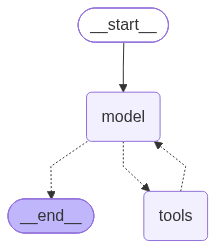

In [22]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools = [web_search]
)
agent

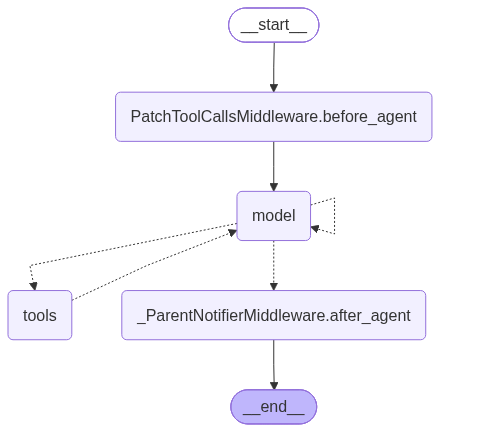

In [21]:
from deepagents import create_deep_agent

deepagent = create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher. Use web search when current information is required."
)
deepagent

In [24]:
res = deepagent.invoke({"messages":[{"role":"user","content":"what is deepagents. "}]})
res

{'messages': [HumanMessage(content='what is deepagents. ', additional_kwargs={}, response_metadata={}, id='9fd63961-768e-4753-b932-1ce71c52407f'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '4jj441fk8', 'function': {'arguments': '{"query":"deepagents langchain"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 2862, 'total_tokens': 2891, 'completion_time': 0.082337113, 'completion_tokens_details': None, 'prompt_time': 0.217794738, 'prompt_tokens_details': None, 'queue_time': 0.053284438, 'total_time': 0.300131851}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1634a-7023-72d2-8ce6-6d07cb274957-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'deepagents langchain'}, 'id': '4jj441fk8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_m

In [25]:
res["messages"][-1].content

'# Deep Agents\n\n**Deep Agents** (`deepagents`) is a standalone, open-source library from LangChain for building LLM-powered agents. It\'s the "harness" layer of LangChain\'s agent stack, built on top of LangChain\'s core building blocks and using the **LangGraph** runtime for durable execution, streaming, and human-in-the-loop features.\n\n## Where it fits in the stack\n\nLangChain describes three composable layers:\n- **LangGraph** — the agent *runtime* (most control, least abstraction)\n- **LangChain** — the agent *framework* (abstractions + integrations, with a minimal agent harness)\n- **Deep Agents** — the agent *harness* (most opinionated, ships with best practices around context management)\n\n## Core capabilities\n\n- **File systems for context management** — a virtual filesystem agents use to read/write and offload context\n- **Subagent spawning** — agents can delegate work to specialized subagents\n- **Long-term memory**\n- **Task planning** (optional) — a planning tool ins